In [63]:
import uproot
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, peak_widths, savgol_filter
import pandas

plt.rcParams["figure.dpi"] = 150

In [174]:
def plot_with_peaks(signal, n_bins, prominence=None, xlabel="", title="", xlims=None, savgol_window=None, savgol_strength=1.0, clip_counts=None, plt_show=True):
    counts, bins = np.histogram(signal, bins=n_bins)
    if savgol_window is not None:
        background = savgol_filter(counts, window_length=savgol_window, polyorder=3)
        counts = counts - background * savgol_strength
        
    if clip_counts is not None:
        counts[counts > clip_counts] = clip_counts
    
    bin_width = np.diff(bins).mean()
    bin_centers = (bins[:-1] + bins[1:]) / 2.0
    height_scale = counts.max()

    plt.bar(bin_centers, counts, width=bin_width, align="center")
    if prominence is not None:
        peaks, props = find_peaks(counts, prominence=prominence)
        half_widths = peak_widths(counts, peaks)[0] * bin_width
        for x, y, prom, half_width in zip(
            bin_centers[peaks], counts[peaks], props["prominences"], half_widths
        ):
            plt.errorbar(
                [x], [y], xerr=[half_width],
                c="black", fmt="", capsize=5, elinewidth=0.5, capthick=0.5
            )
            plt.annotate(
                f"{x:.03f} ± {half_width:.03f} MeV",
                (x, y+height_scale*0.03),
                ha="left", fontsize=5
            )

    plt.xlabel(xlabel)
    plt.ylabel("Count")
    plt.ylim(0, max(counts) * 1.1)
    plt.xlim(xlims)
    plt.title(title)
    
    if plt_show:
        plt.show()

# Load CSV

In [4]:
df = pandas.read_csv("archive/bert_hp_1M.csv", comment="#", header=None)
df.columns = [
    "E", "p_x", "p_y", "p_z",
    "x", "y", "z",
    "name", "creator",
    "time", "step", "trackID"
]
print(f"{df.shape[0]:,} gamma rays recorded")
df

17,432,788 gamma rays recorded


,E,p_x,p_y,p_z,x,y,z,name,creator,time,step,trackID
0,0.165071,0.646365,0.460808,-0.608168,-20555.6,-2140.85,-1653.610,gamma,neutronInelastic,15.0773,1,8
1,2.735340,0.525536,-0.260461,-0.809921,-20555.6,-2140.85,-1653.610,gamma,neutronInelastic,15.0685,1,7
2,0.013489,0.099746,0.774498,-0.624663,-20485.0,-2174.47,-1765.060,gamma,eBrem,15.5053,1,42
3,1.016990,0.322441,-0.566525,0.758341,-20574.7,-2232.92,-1691.470,gamma,neutronInelastic,17.8369,1,58
4,0.006363,0.055632,-0.041401,-0.997593,-20602.1,-2343.95,-1695.560,gamma,phot,19.5337,1,69
...,...,...,...,...,...,...,...,...,...,...,...,...
17432783,0.006363,-0.813874,-0.324961,0.481674,22527.5,-4136.67,-653.512,gamma,phot,37.0481,1,254
17432784,0.014117,-0.687050,0.668020,-0.285852,22654.8,-4446.57,-922.682,gamma,eBrem,34.9037,1,260
17432785,1.779000,0.864829,-0.464309,-0.191017,22893.0,-5555.35,-716.504,gamma,neutronInelastic,90.7949,1,265
17432786,0.006350,-0.494886,-0.841348,-0.217302,23213.6,-5669.15,-583.109,gamma,phot,93.6907,1,279


In [185]:
carbon_e_range = df["E"].between(4.2, 5)
carbon_e_zoom = df["E"].between(4.4379, 4.4381)
wide_e_range = df["E"].between(1.0, 10.0)
inelastic_creator = df["creator"] == "neutronInelastic"
shallow = df["z"].between(-200.0, 0.0)

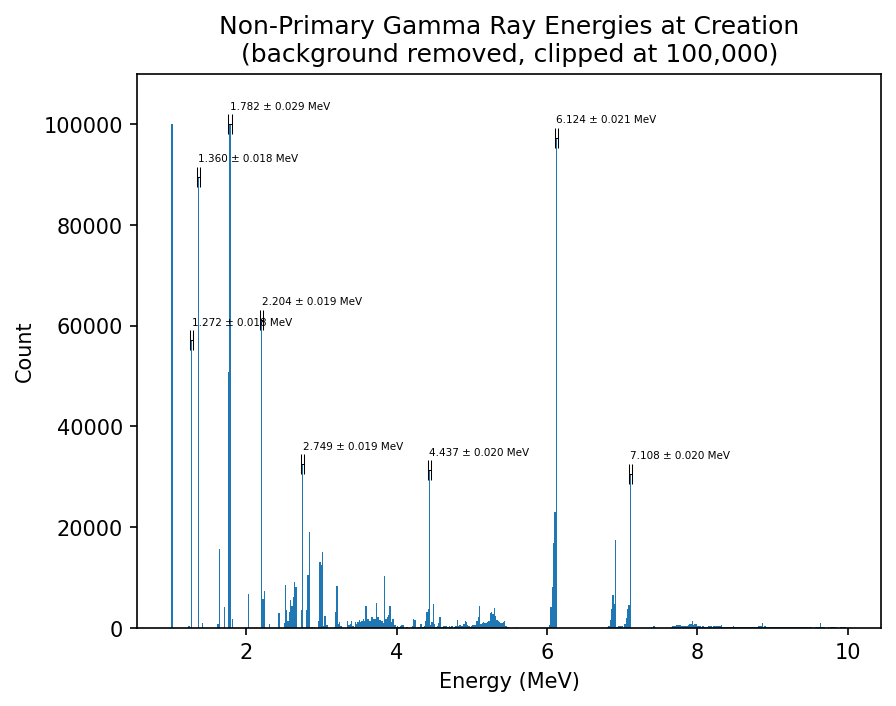

In [179]:
energies = df[wide_e_range]["E"]
plot_with_peaks(
    energies,
    512, 30000.0,
    xlabel="Energy (MeV)", title="Non-Primary Gamma Ray Energies at Creation\n(background removed, clipped at 100,000)",
    savgol_window=101,
    savgol_strength=0.8,
    clip_counts=100_000
)

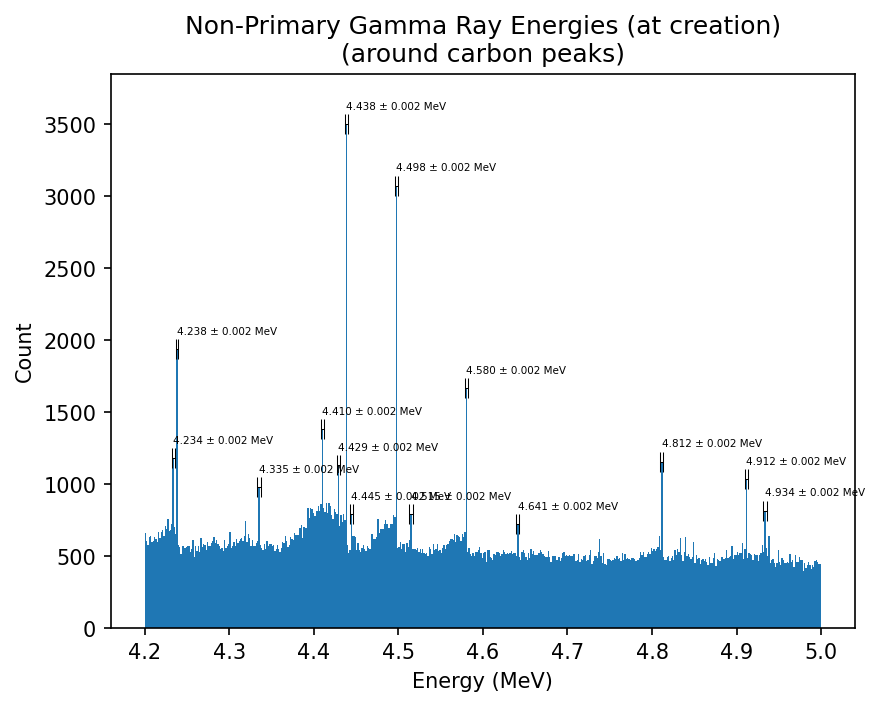

In [192]:
energies = df[carbon_e_range]["E"]
plot_with_peaks(
    energies,
    512, 200.0, clip_counts=3500,
    xlabel="Energy (MeV)", title="Non-Primary Gamma Ray Energies (at creation)\n(around carbon peaks)"
)

/var/folders/5j/qsd63dfs2pdfpfcy7c85d27w0000gn/T/ipykernel_86672/3964359377.py:33: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, max(counts) * 1.1)


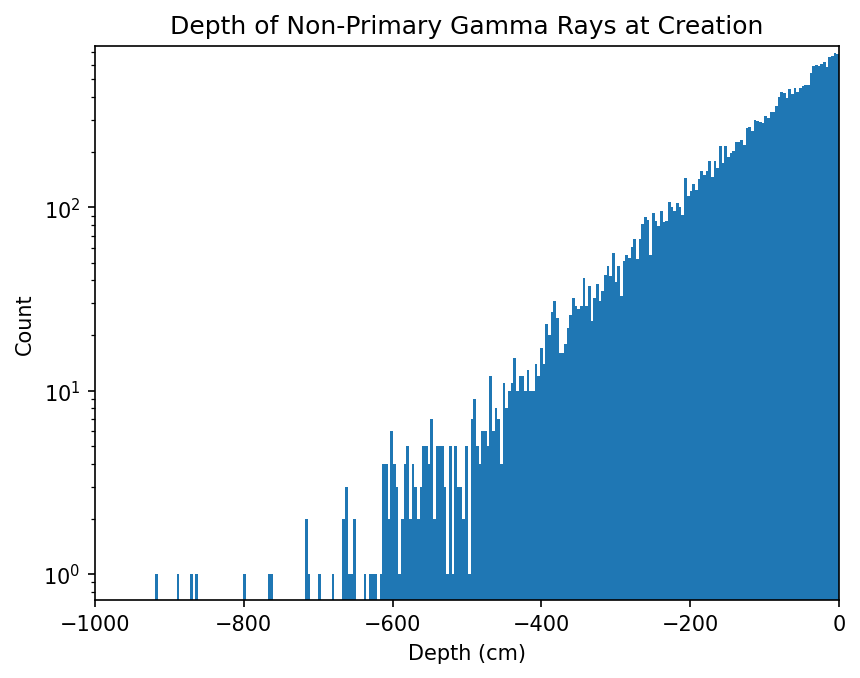

In [194]:
plt.yscale("log")
mctaggart = df["creator"].isin(["nCapture", "RadioactiveDecay", "neutronInelastic"])
plot_with_peaks(df[mctaggart & carbon_e_zoom]["z"] / 10, 256, xlabel="Depth (cm)", title="Depth of Non-Primary Gamma Rays at Creation", xlims=(-1000,0))

In [191]:
print(f"z mean: {-np.mean(df[mctaggart & carbon_e_zoom]['z'])/10:.01f} cm, z median: {-np.median(df[mctaggart & carbon_e_zoom]['z'])/10:.01f}")

z mean: 106.3 cm, z median: 77.1


In [49]:
process_name, process_count = np.unique(df["creator"], return_counts=True)

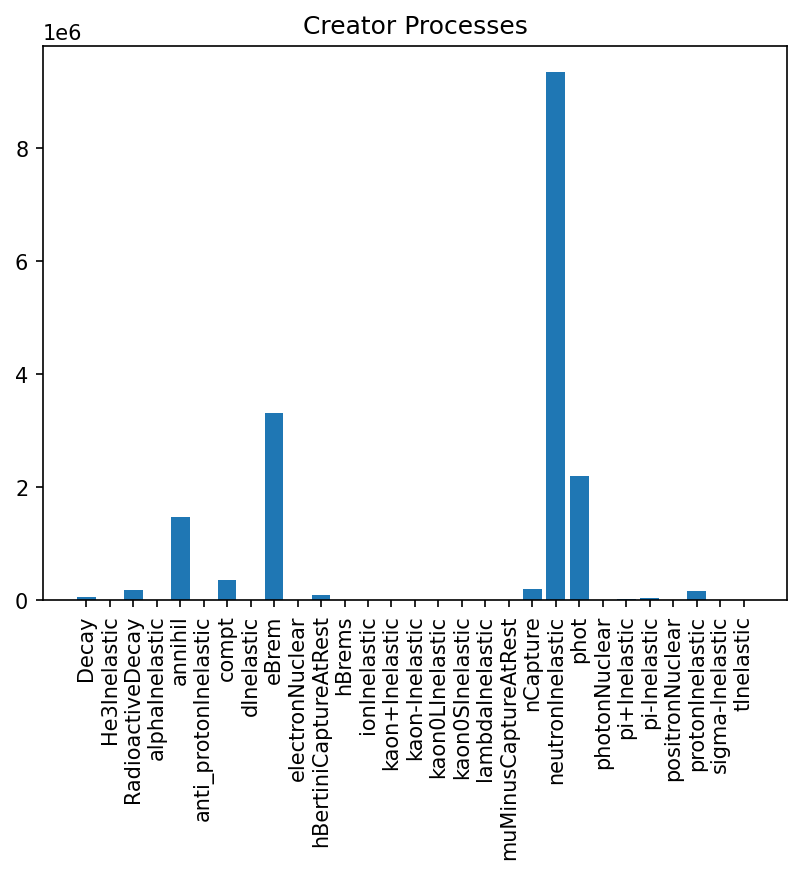

In [53]:
plt.bar(process_name, process_count)
plt.xticks(rotation="vertical")
plt.title("Creator Processes")
plt.show()

/var/folders/5j/qsd63dfs2pdfpfcy7c85d27w0000gn/T/ipykernel_86672/1910776584.py:35: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, max(counts) * 1.1)


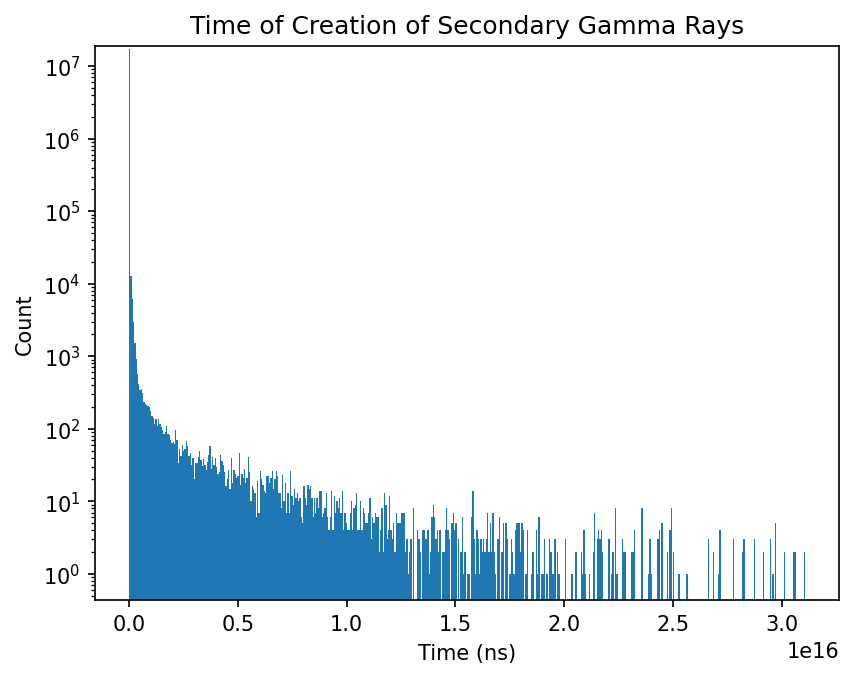

In [102]:
plt.yscale("log")
plot_with_peaks(df["time"], 512, title="Time of Creation of Secondary Gamma Rays", xlabel="Time (ns)")

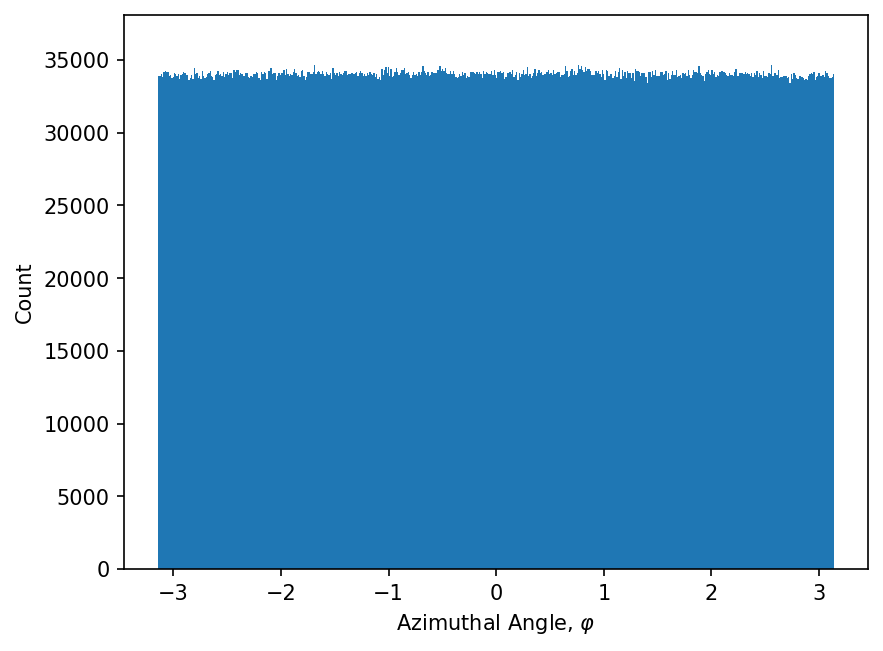

/Users/justjayiguess/Documents/Code/Geant4/ground-carbon/analysis/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in arccos
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [ ]:
phi = np.atan2(df["p_x"], df["p_y"])
plot_with_peaks(phi, 512, xlabel="Azimuthal Angle, $\\varphi$")

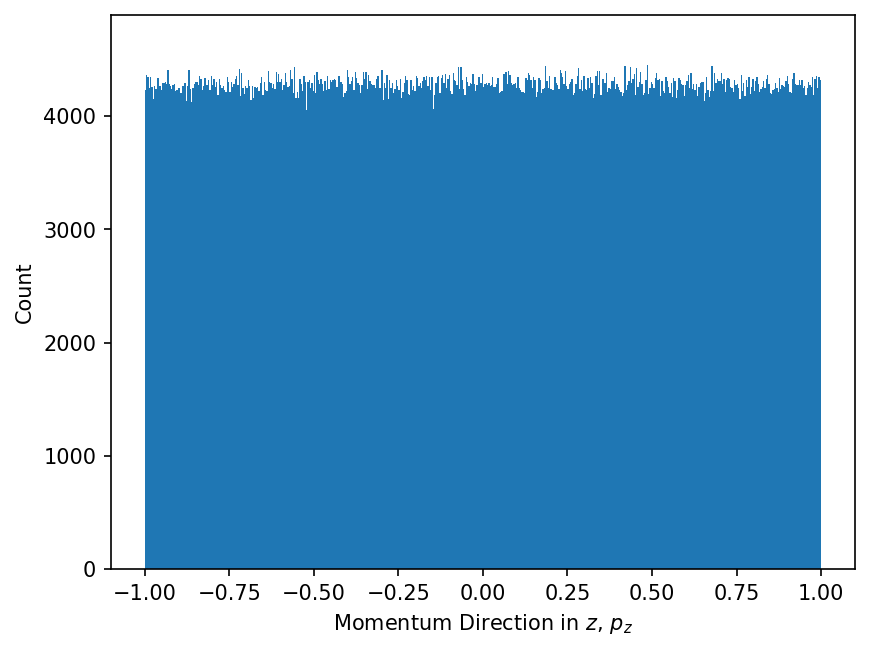

In [129]:

plot_with_peaks(df[df["creator"] == "phot"]["p_z"], 512, xlabel="Momentum Direction in $z$, $p_z$")

# ROOT

In [3]:
file = uproot.open("archive/run_1_000_000_all_secondaries.root")
print(f"Trees: {file.keys()}")
data = file[file.keys()[0]]

def load(key):
    return np.concat(data[key].array(library="np")) # type: ignore

print("Keys:", ", ".join(data.keys()))

Trees: ['Results;1']
Keys: KE, MomDirX, MomDirY, MomDirZ, PosX, PosY, PosZ, Time, Name, TrackID


In [4]:
# energy = load("KE")
# pos_z = load("PosZ")
name = load("Name")

(array([968.,  73., 102.,  59.,  49.,  37.,   5.,  13.,   2.,   7.]),
 array([ 0. ,  2.2,  4.4,  6.6,  8.8, 11. , 13.2, 15.4, 17.6, 19.8, 22. ]),
 <BarContainer object of 10 artists>)

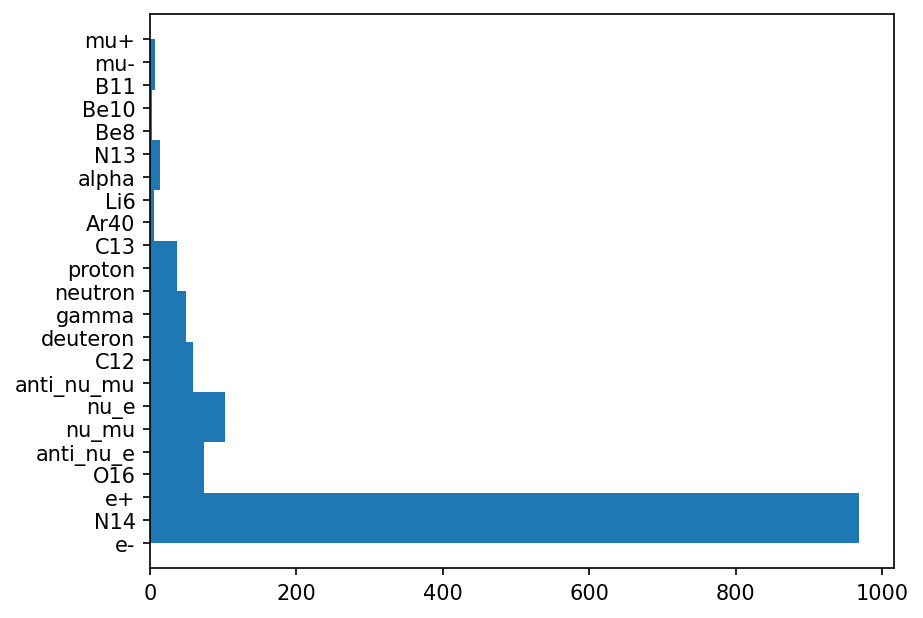

In [ ]:
plt.hist(name, orientation="horizontal")

In [7]:
full_energy_spectrum = (0.04 < energy) & (energy < 7)
carbon_silicon_spectrum = (4.4 < energy) & (energy < 4.5)
hydrogen_peak = (2.2 < energy) & (energy < 2.3)
low_energy_spectrum = (1 < energy) & (energy < 3)

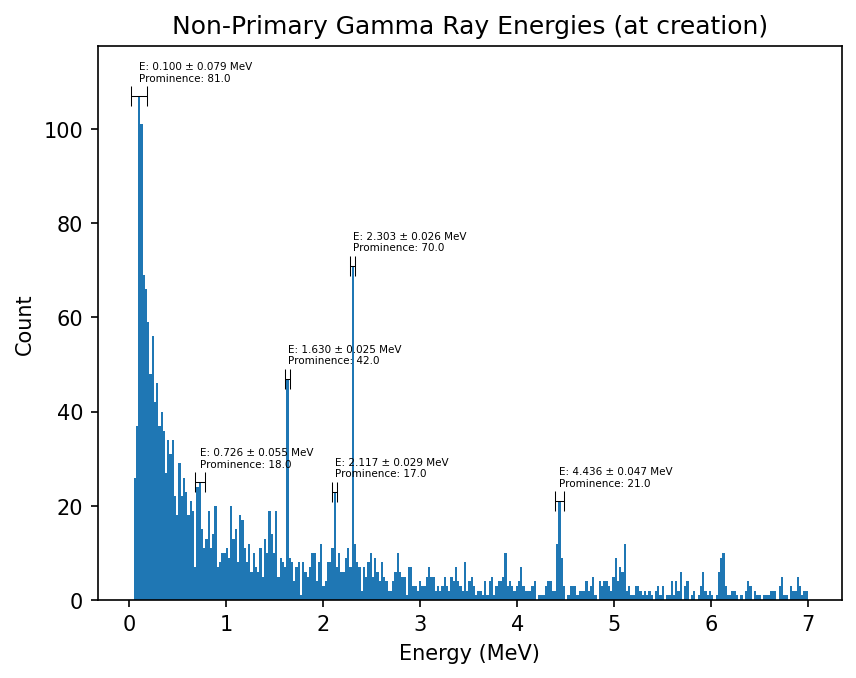

In [11]:
plot_with_peaks(energy[full_energy_spectrum], 300, 15)

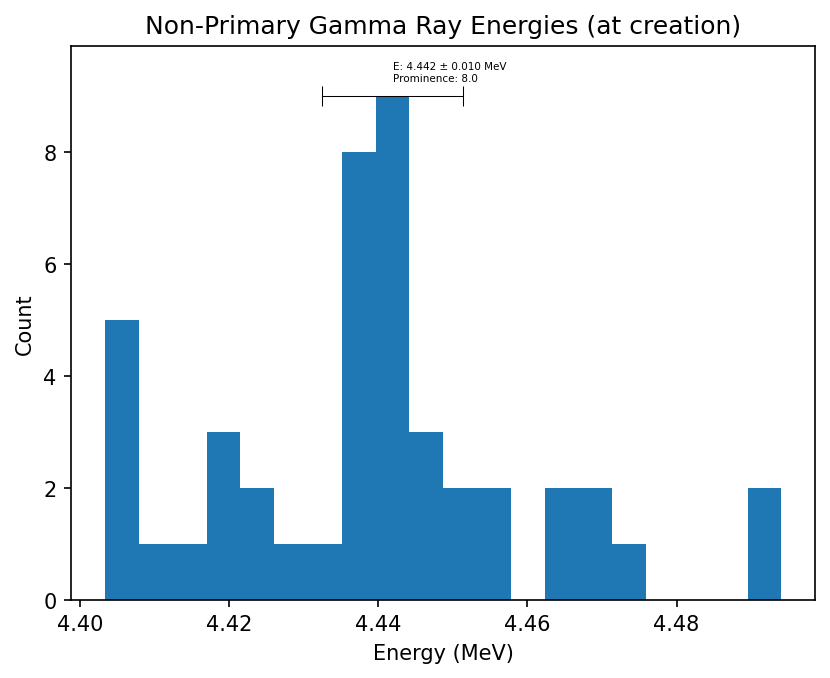

In [12]:
plot_with_peaks(energy[carbon_silicon_spectrum], 20, 4)

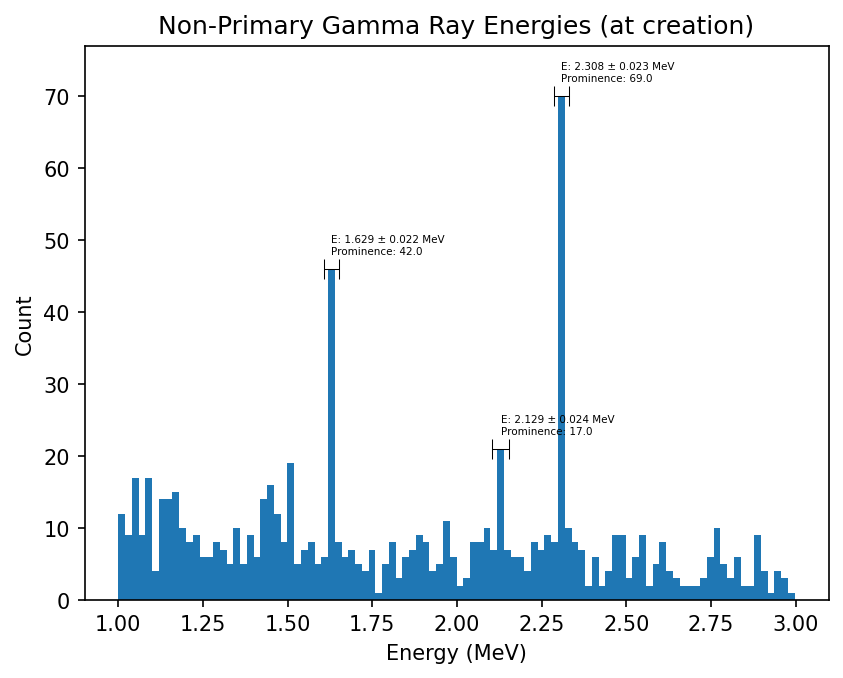

In [96]:
plot_with_peaks(energy[low_energy_spectrum], 100, 15)

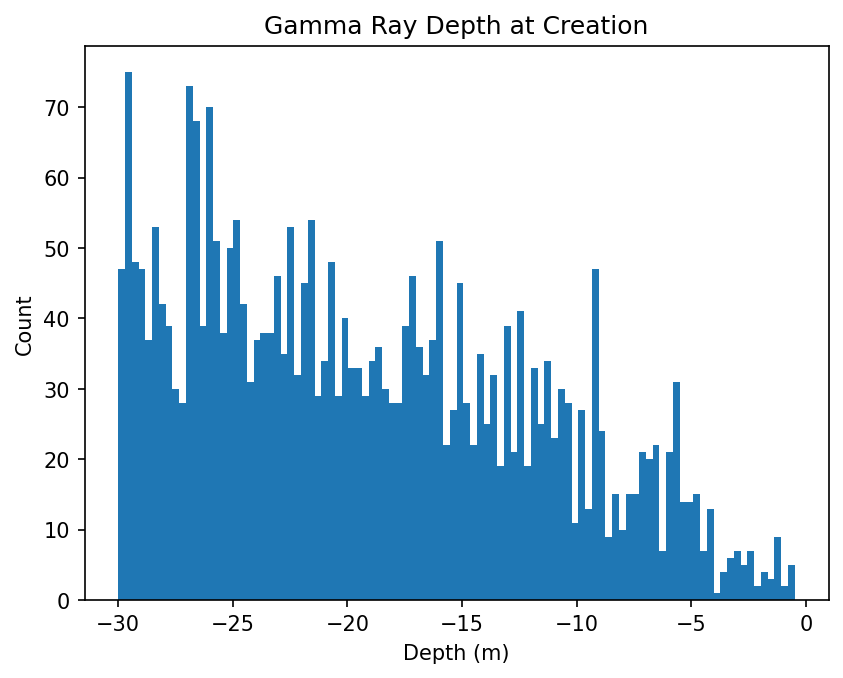

In [97]:
plt.hist(pos_z/1000, bins=100)
plt.xlabel("Depth (m)")
plt.ylabel("Count")
plt.title("Gamma Ray Depth at Creation")
plt.show()

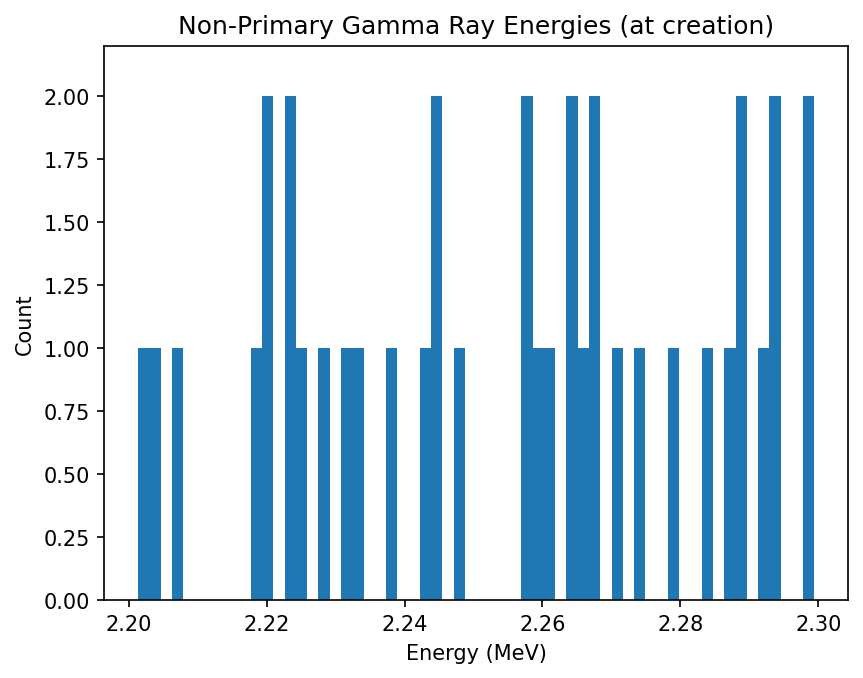

In [108]:
plot_with_peaks(energy[hydrogen_peak], 60, 10)